# Entrega 2 · Análisis exploratorio

* **Grupo:** Grupo 7
* **Integrantes:** Nicolás López · Felipe Haudet · Franco Sorrentino · Facundo Caiña · Lucca Burgos
* **Pregunta del proyecto:** ¿Qué factores influyen para que un jugador llegue a un club top 20 de Europa?
* **Variable objetivo:** `es_destino_top_20` — el club de destino está entre los 20 primeros del
  coeficiente de clubes de UEFA de las últimas diez temporadas.

El dataset lo produce nuestro propio pipeline de Airflow (`pipeline_fichajes`), que cruza tres
fuentes: el ranking de clubes de UEFA, las altas por club y temporada de Transfermarkt, y las
estadísticas de rendimiento de FotMob. **Una fila es un fichaje**, no un jugador.

## 0 · Qué cambió desde la Entrega 1

Cuatro correcciones, todas en el pipeline:

1. **El top 20 sale del coeficiente de clubes de UEFA** de diez temporadas, no del ranking de
   Transfermarkt, que se reordena solo.
2. **Se guarda el bronce de Transfermarkt** (HTML crudo comprimido, particionado por club y
   temporada). Antes se parseaba al vuelo y no quedaba nada.
3. **El club de origen quedó enriquecido**: país, liga, si la liga es top 5, si el club es
   europeo, ranking y coeficiente UEFA del club y del país, y si es un filial.
4. **El pipeline se dispara solo**: compara una huella de las fuentes contra la de la última
   corrida, en vez de mirar el reloj.

Y una decisión de alcance tomada para esta entrega: **cinco temporadas** de fichajes en vez de tres.

## 1 · Carga

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 60)
plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

# Subir el csv en archivos

RUTA = "fichajes.csv"

df = pd.read_csv(RUTA, low_memory=False)
print(f"{len(df):,} filas x {df.shape[1]} columnas")

13,063 filas x 107 columnas


## 2 · El perfil del dataset

cuántas filas, qué es una fila, cuál es la clave, dónde
hay nulos y por qué, cuál es el objetivo y cómo está distribuido.

In [2]:
descriptivas = [c for c in df.columns if not c.startswith("stat_")]
metricas = [c for c in df.columns if c.startswith("stat_")]

print(f"filas: {len(df):,}")
print(f"columnas: {df.shape[1]}  ({len(descriptivas)} descriptivas + {len(metricas)} métricas stat_*)")
print("\nuna fila = un fichaje (jugador + club de destino + temporada)")
print(f"  fichajes .......... {len(df):,}")
print(f"  jugadores únicos .. {df['jugador_tm_id'].nunique():,}")
print(f"  clubes de destino . {df['club_destino'].nunique()}")
print(f"  clubes de origen .. {df['club_origen'].nunique():,}")
print(f"  temporadas ........ {', '.join(sorted(df['temporada_fichaje'].unique()))}")

repetidos = (df["jugador_tm_id"].value_counts() > 1).sum()
print(f"\n{repetidos:,} jugadores aparecen en más de una fila: las filas NO son independientes.")
print("Para la Unidad 3 importa: separar train/test al azar deja al mismo jugador de los dos lados.")

filas: 13,063
columnas: 107  (42 descriptivas + 65 métricas stat_*)

una fila = un fichaje (jugador + club de destino + temporada)
  fichajes .......... 13,063
  jugadores únicos .. 9,862
  clubes de destino . 188
  clubes de origen .. 2,030
  temporadas ........ 2022/2023, 2023/2024, 2024/2025, 2025/2026, 2026/2027

2,315 jugadores aparecen en más de una fila: las filas NO son independientes.
Para la Unidad 3 importa: separar train/test al azar deja al mismo jugador de los dos lados.


In [3]:
print("clave primaria: operacion_id (el id que Transfermarkt le da a cada traspaso)")
print(f"  duplicados ..... {df['operacion_id'].duplicated().sum()}")
print(f"  nulos .......... {df['operacion_id'].isna().sum()}")
print(f"  valores únicos . {df['operacion_id'].nunique():,} sobre {len(df):,} filas")
print(f"\nfilas duplicadas completas: {df.duplicated().sum()}")

print("\ntipos de dato:")
print(df.dtypes.value_counts().to_string())

constantes = df.columns[df.nunique() <= 1].tolist()
print(f"\ncolumnas constantes ({len(constantes)}): {constantes}")
print("  -> son metadata de la corrida del pipeline, no datos del fichaje. Se van.")

clave primaria: operacion_id (el id que Transfermarkt le da a cada traspaso)
  duplicados ..... 0
  nulos .......... 0
  valores únicos . 13,063 sobre 13,063 filas

filas duplicadas completas: 0

tipos de dato:
float64    76
str        17
bool        9
int64       4
object      1

columnas constantes (2): ['uefa_actualizado_el', 'extraido_el']
  -> son metadata de la corrida del pipeline, no datos del fichaje. Se van.


In [4]:
# Nulos separados por CAUSA.

CAUSA = {
    "coste_fichaje_eur": "estructural — un pase libre o una cesión no tienen monto",
    "nacionalidad_2": "estructural — la mayoría tiene una sola nacionalidad",
    "club_origen_ranking_uefa": "por diseño — el club no está en el ranking, o es un filial",
    "club_origen_coeficiente_uefa": "por diseño — ídem",
    "salto_ranking_uefa": "por diseño — necesita el ranking de los dos clubes",
    "sube_de_categoria": "por diseño — ídem",
    "club_origen_pais_ranking_uefa": "por diseño — país fuera de las 55 asociaciones de UEFA",
    "club_origen_pais_coeficiente_uefa": "por diseño — ídem",
    "club_origen_pais": "faltante — Transfermarkt no publicó el país del club",
    "club_origen_liga": "faltante — ídem con la liga",
    "club_origen_liga_id": "faltante — ídem",
    "altura_cm": "faltante — 91% porque el jugador no tiene perfil en FotMob; el resto, FotMob no publicó la altura aunque el perfil existe",
    "pie": "faltante — 90% porque el jugador no tiene perfil en FotMob; el resto, ídem con el pie",
    "posicion_fotmob": "faltante — el jugador no tiene perfil en FotMob (100% de los casos)",
    "jugador_fotmob_id": "faltante — el jugador no tiene perfil en FotMob",
}

nulos = (df[descriptivas].isna().mean() * 100).round(1)
nulos = nulos[nulos > 0].sort_values(ascending=False)
print(pd.DataFrame({"nulos_%": nulos,
                    "causa": [CAUSA.get(c, "?") for c in nulos.index]}).to_string())

sin_metricas = ~df["tiene_historial"].astype("boolean").fillna(False)
print(f"\nde las {len(metricas)} columnas stat_*:")
print(f"  {sin_metricas.sum():,} filas ({sin_metricas.mean():.1%}) no tienen NINGUNA métrica")
print(f"  mediana de métricas por fila: {df[metricas].notna().sum(axis=1).median():.0f}")

                                   nulos_%                                                                                                                      causa
nacionalidad_2                        66.5                                                                       estructural — la mayoría tiene una sola nacionalidad
coste_fichaje_eur                     63.1                                                                   estructural — un pase libre o una cesión no tienen monto
club_origen_ranking_uefa              53.5                                                                 por diseño — el club no está en el ranking, o es un filial
sube_de_categoria                     53.5                                                                                                          por diseño — ídem
salto_ranking_uefa                    53.5                                                                         por diseño — necesita el ranking de los dos clubes
club

> * **Estructural** — no se imputa nunca. Poner 0 en `coste_fichaje_eur` sería decir «se pagó cero»,
>   que no es lo mismo que «no hubo pago». Si se usara, iría como dos columnas: un booleano
>   `hubo_monto` y el monto sólo donde existe.
> * **Por diseño** — tampoco. El nulo de `club_origen_ranking_uefa` dice «este club no está entre los
>   554 de UEFA, o es un filial»: eso es información sobre el jugador, no ausencia de información.
>   Imputar la media lo convertiría en un club europeo promedio, que es falso.

### Los nulos de las 65 `stat_*`

---


In [5]:
con_hist = df[df["tiene_historial"].astype("boolean").fillna(False)]
es_arquero = con_hist["grupo_posicion"].eq("Arquero") if "grupo_posicion" in con_hist \
    else con_hist["posicion_tm"].eq("Goalkeeper")

ARQUERO = ["stat_saves", "stat_save_percentage", "stat_goals_conceded", "stat_high_claims",
           "stat_penalty_saves", "stat_penalty_save_%", "stat_goals_prevented",
           "stat_acted_as_sweeper", "stat_error_led_to_goal"]
SEGUIMIENTO = ["stat_top_speed", "stat_total_distance_covered", "stat_number_of_sprints",
               "stat_running", "stat_sprinting", "stat_jogging", "stat_walking",
               "stat_line-breaking_passes"]
EVENTO_RARO = ["stat_penalty_goals", "stat_penalties_awarded"]

print("1) MÉTRICAS DE ARQUERO — nulo estructural POR POSICIÓN")
print(f"   {len(ARQUERO)} columnas. Un defensor no ataja: ese nulo es correcto.\n")
print(f"   {'columna':30}{'global':>9}{'en arqueros':>14}{'en jug. de campo':>19}")
for c in ARQUERO:
    print(f"   {c:30}{con_hist[c].notna().mean():>8.1%}"
          f"{con_hist.loc[es_arquero, c].notna().mean():>14.1%}"
          f"{con_hist.loc[~es_arquero, c].notna().mean():>19.1%}")

print("\n2) MÉTRICAS DE SEGUIMIENTO (GPS) — cobertura de la fuente, y es TEMPORAL")
print(f"   {len(SEGUIMIENTO)} columnas. FotMob las empezó a publicar hace poco:\n")
for t, g in con_hist.groupby("temporada_stats"):
    print(f"   {t}   n={len(g):>5}   con velocidad máxima: {g['stat_top_speed'].notna().mean():>6.1%}"
          f"   con pases rompelíneas: {g['stat_line-breaking_passes'].notna().mean():>6.1%}")

print("\n   Y lo peor no es la cobertura baja, es CON QUIÉN se correlaciona:")
tiene_gps = con_hist["stat_top_speed"].notna()
print(f"   filas CON dato de GPS: {tiene_gps.sum():>6,}  ->  tasa de top 20 "
      f"{con_hist.loc[tiene_gps, 'es_destino_top_20'].mean():.1%}")
print(f"   filas SIN dato de GPS: {(~tiene_gps).sum():>6,}  ->  tasa de top 20 "
      f"{con_hist.loc[~tiene_gps, 'es_destino_top_20'].mean():.1%}")
print(f"   de liga top 5:  con GPS {con_hist.loc[tiene_gps, 'club_origen_liga_es_top5'].mean():.1%}"
      f"  |  sin GPS {con_hist.loc[~tiene_gps, 'club_origen_liga_es_top5'].mean():.1%}")
print("   ^ el simple hecho de TENER el dato ya predice el objetivo, y no porque el")
print("     jugador corra más: porque FotMob publica tracking en las ligas grandes.")

print("\n3) EVENTOS RAROS — el nulo significa CERO, no «se desconoce»")
for c in EVENTO_RARO + ["stat_goals", "stat_red_cards"]:
    v = pd.to_numeric(con_hist[c], errors="coerce")
    familia = "evento raro" if c in EVENTO_RARO else "normal"
    print(f"   {c:28} cobertura {v.notna().mean():>6.1%} | mínimo {v.min():.0f} | "
          f"ceros explícitos {int((v == 0).sum()):>5}   ({familia})")

1) MÉTRICAS DE ARQUERO — nulo estructural POR POSICIÓN
   9 columnas. Un defensor no ataja: ese nulo es correcto.

   columna                          global   en arqueros   en jug. de campo
   stat_saves                        7.2%         93.9%               0.2%
   stat_save_percentage              7.1%         92.2%               0.2%
   stat_goals_conceded               7.2%         93.9%               0.2%
   stat_high_claims                  6.7%         87.1%               0.2%
   stat_penalty_saves                5.7%         73.9%               0.2%
   stat_penalty_save_%               5.7%         73.9%               0.2%
   stat_goals_prevented              5.6%         72.8%               0.1%
   stat_acted_as_sweeper             6.4%         82.9%               0.2%
   stat_error_led_to_goal            7.2%         93.9%               0.2%

2) MÉTRICAS DE SEGUIMIENTO (GPS) — cobertura de la fuente, y es TEMPORAL
   8 columnas. FotMob las empezó a publicar hace poco:

   2

Las tres causas piden cosas distintas, y confundirlas sale caro:

**1. Las de arquero** están bien como están. Cubren el 94 % de los arqueros y el 0,2 % del resto: el
nulo dice «este jugador no es arquero», que ya lo dice `grupo_posicion`.

**2. Las de seguimiento son las peligrosas**, y son las que más caro se pagarían. Su nulo no depende
del jugador sino de **dónde y cuándo** se jugó: **el simple hecho de tener el dato predice el
objetivo**. Los fichajes con GPS van a un club top 20 la mayoria de las veces, ya que son datos que vienen de ligas grandes

**3. Los eventos raros** son el caso más sutil. `stat_penalty_goals` tiene **mínimo 1 y ni un solo
cero explícito**: FotMob publica la métrica sólo si el jugador convirtió al menos un penal. Ahí el
nulo significa **cero**, e imputarlo con 0 es lo correcto. Compará con `stat_goals`, que sí trae
miles de ceros explícitos: en esa columna un nulo significa «no se sabe», e imputarla con 0 sería
inventar que el jugador no convirtió.

es_destino_top_20
False    0.9197
True     0.0803

1049 positivos sobre 13,063 filas = 8.03%
1 positivo cada 12.5 filas

por temporada:
                   filas  positivos  tasa_%
temporada_fichaje                          
2022/2023           2711        224    8.26
2023/2024           2706        214    7.91
2024/2025           2773        217    7.83
2025/2026           2839        217    7.64
2026/2027           2034        177    8.70


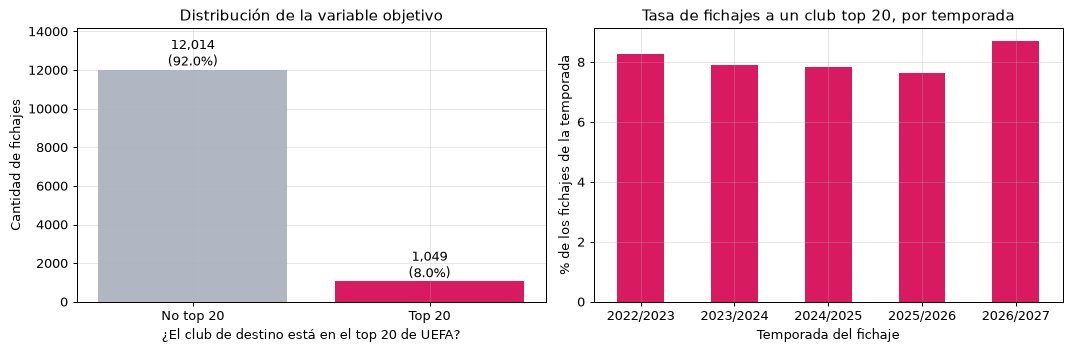

In [6]:
# LA DISTRIBUCIÓN DEL OBJETIVO: el número más importante de esta entrega.
y = df["es_destino_top_20"].astype("boolean").fillna(False)

print(df["es_destino_top_20"].value_counts(normalize=True).round(4).to_string())
print(f"\n{int(y.sum())} positivos sobre {len(df):,} filas = {y.mean():.2%}")
print(f"1 positivo cada {len(df) / max(int(y.sum()), 1):.1f} filas")

por_temp = df.groupby("temporada_fichaje").agg(
    filas=("operacion_id", "size"), positivos=("es_destino_top_20", "sum"))
por_temp["tasa_%"] = (por_temp.positivos / por_temp.filas * 100).round(2)
print("\npor temporada:")
print(por_temp.to_string())

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
conteo = y.value_counts().sort_index()
ax[0].bar(["No top 20", "Top 20"], conteo.values, color=["#b0b7c3", "#d81b60"])
for i, v in enumerate(conteo.values):
    ax[0].text(i, v, f"{v:,}\n({v / len(df):.1%})", ha="center", va="bottom")
ax[0].set_title("Distribución de la variable objetivo")
ax[0].set_ylabel("Cantidad de fichajes")
ax[0].set_xlabel("¿El club de destino está en el top 20 de UEFA?")
ax[0].set_ylim(0, conteo.max() * 1.18)

por_temp["tasa_%"].plot(kind="bar", ax=ax[1], color="#d81b60")
ax[1].set_title("Tasa de fichajes a un club top 20, por temporada")
ax[1].set_ylabel("% de los fichajes de la temporada")
ax[1].set_xlabel("Temporada del fichaje")
ax[1].tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

### Asimetría: qué habría que transformar

Lo último del perfil. Una columna con cola larga se lleva puesta cualquier medida basada en medias,
y hay que saber cuáles son antes de medir nada.

las 10 más asimétricas:
coste_fichaje_eur          3.98
club_destino_id            3.88
stat_successful_crosses    2.97
club_origen_id             2.88
stat_goals                 2.86
stat_penalties_conceded    2.81
stat_xg                    2.80
stat_headed_shots          2.76
stat_penalties_awarded     2.76
stat_xgot                  2.71

qué pasa al pasarlas a escala logarítmica:
  coste_fichaje_eur                skew   3.98  ->  con log1p  -0.15
  club_origen_coeficiente_uefa     skew   1.23  ->  con log1p  -0.07
  club_destino_coeficiente_uefa    skew   2.01  ->  con log1p   0.72
  stat_goals                       skew   2.86  ->  con log1p   0.57

club_destino_id y club_origen_id salen altas, pero
son identificadores. No sirve medir simetria


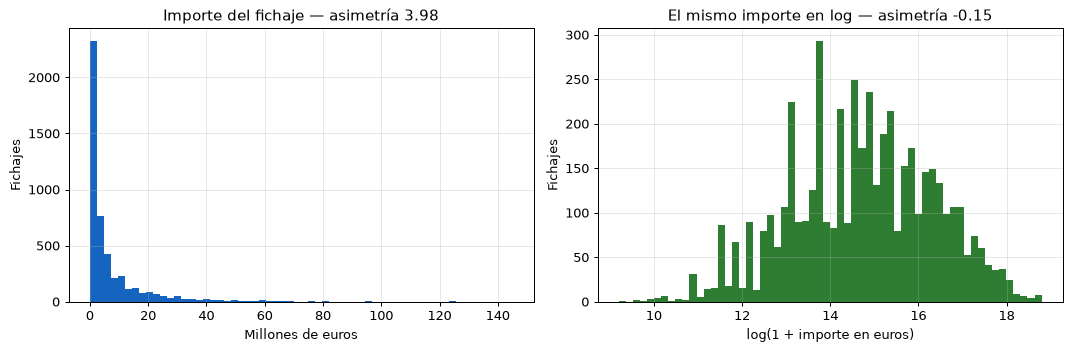

In [7]:
numericas = df.select_dtypes("number")
asimetria = numericas.skew().sort_values(ascending=False)

print("las 10 más asimétricas:")
print(asimetria.head(10).round(2).to_string())

print("\nqué pasa al pasarlas a escala logarítmica:")
for c in ["coste_fichaje_eur", "club_origen_coeficiente_uefa",
          "club_destino_coeficiente_uefa", "stat_goals"]:
    v = pd.to_numeric(df[c], errors="coerce").dropna()
    print(f"  {c:32} skew {v.skew():6.2f}  ->  con log1p {np.log1p(v).skew():6.2f}")

print("\nclub_destino_id y club_origen_id salen altas, pero")
print("son identificadores. No sirve medir simetria")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
precio = pd.to_numeric(df["coste_fichaje_eur"], errors="coerce").dropna()
ax[0].hist(precio / 1e6, bins=60, color="#1565c0")
ax[0].set_title(f"Importe del fichaje — asimetría {precio.skew():.2f}")
ax[0].set_xlabel("Millones de euros")
ax[0].set_ylabel("Fichajes")
ax[1].hist(np.log1p(precio), bins=60, color="#2e7d32")
ax[1].set_title(f"El mismo importe en log — asimetría {np.log1p(precio).skew():.2f}")
ax[1].set_xlabel("log(1 + importe en euros)")
ax[1].set_ylabel("Fichajes")
plt.tight_layout()
plt.show()

## 3 · Columnas nuevas

In [8]:
# grupo_posicion: las 16 etiquetas de Transfermarkt, agrupadas por el trabajo real de cada
# rol en la cancha. No alcanza con 4 puestos amplios: un lateral no defiende igual que un
# central (también ataca por punta), y un mediocampista ofensivo no juega igual que uno
# defensivo (uno crea juego, el otro recupera pelotas).
GRUPOS_POSICION = {
    "Goalkeeper": "Arquero",
    "Centre-Back": "Defensor central", "Defender": "Defensor central",
    "Right-Back": "Lateral", "Left-Back": "Lateral",
    "Defensive Midfield": "Mediocampo defensivo",
    "Central Midfield": "Mediocampo ofensivo", "Attacking Midfield": "Mediocampo ofensivo",
    "Right Midfield": "Mediocampo ofensivo", "Left Midfield": "Mediocampo ofensivo",
    "Midfielder": "Mediocampo ofensivo",
    "Centre-Forward": "Delantero centro", "Second Striker": "Delantero centro",
    "Striker": "Delantero centro",
    "Left Winger": "Delantero extremo", "Right Winger": "Delantero extremo",
}
df["grupo_posicion"] = df["posicion_tm"].map(GRUPOS_POSICION)

sin_mapear = df.loc[df["grupo_posicion"].isna(), "posicion_tm"].unique()
assert len(sin_mapear) == 0, f"posiciones sin grupo asignado: {sin_mapear}"

print(df["grupo_posicion"].value_counts().to_string())

grupo_posicion
Mediocampo ofensivo     2559
Defensor central        2186
Delantero extremo       2159
Delantero centro        2073
Lateral                 1811
Arquero                 1231
Mediocampo defensivo    1044


In [9]:
# -------------------------------------------------------------------------
# MÉTRICA: score_posicion
# -------------------------------------------------------------------------
# Puntaje único de rendimiento previo al fichaje. Permite comparar de forma
# justa a jugadores de posiciones completamente distintas.
#
# ¿CÓMO SE CALCULA? (Z-Score)
# 1. Base y Especialidad: Se evalúa el volumen de juego (minutos/partidos)
#    más 5 métricas clave específicas de cada rol (ej. atajadas para el
#    arquero, goles para el delantero).
# 2. Estandarización: Cada métrica se compara SOLO con los jugadores de ese
#    mismo rol utilizando la fórmula Z-score:
#    Z = (Valor del jugador - Promedio del grupo) / Desviación estándar
#    Esto traduc, por ej: quites vs. goles, a una escala común.
#
# ¿POR QUÉ SE PROMEDIAN LOS RESULTADOS EN LUGAR DE SUMARLOS?
# Es una estrategia para manejar la falta de datos. Si a un jugador le falta
# el registro de una estadística, promediar los Z-scores permite calcular un
# puntaje válido con las métricas restantes, evitando que su score colapse.
# -------------------------------------------------------------------------

BASE = ["stat_minutes", "stat_matches"]

ESPECIFICAS = {
    "Arquero": ["stat_saves", "stat_save_percentage", "stat_goals_conceded_inv",
                "stat_goals_prevented", "stat_high_claims"],
    "Defensor central": ["stat_tackles", "stat_interceptions", "stat_duels_won_%",
                          "stat_aerials_won_%", "stat_recoveries"],
    "Lateral": ["stat_tackles", "stat_interceptions", "stat_duels_won_%",
                "stat_successful_crosses", "stat_recoveries"],
    "Mediocampo defensivo": ["stat_tackles", "stat_interceptions", "stat_duels_won_%",
                              "stat_recoveries", "stat_pass_accuracy"],
    "Mediocampo ofensivo": ["stat_pass_accuracy", "stat_chances_created", "stat_assists",
                             "stat_dribbles_success_rate", "stat_possession_won_final_3rd"],
    "Delantero centro": ["stat_goals", "stat_xg", "stat_shots_on_target",
                          "stat_touches_in_opposition_box", "stat_aerials_won_%"],
    "Delantero extremo": ["stat_goals", "stat_assists", "stat_dribbles_success_rate",
                           "stat_successful_crosses", "stat_big_chances_created"],
}
df["stat_goals_conceded_inv"] = -pd.to_numeric(df["stat_goals_conceded"], errors="coerce")


def calcular_score(datos, base=BASE, especificas=ESPECIFICAS, grupo="grupo_posicion"):
    """z de cada componente DENTRO de su rol, promediados. NaN si no hay historial."""
    partes = []
    for grp, cols in especificas.items():
        sub = datos[datos[grupo] == grp]
        zetas = []
        for col in base + cols:
            v = pd.to_numeric(sub[col], errors="coerce")
            g = v.groupby(sub[grupo])
            desvio = g.transform("std").replace(0, np.nan)   # un grupo de 1 daría infinito
            zetas.append((v - g.transform("mean")) / desvio)
        partes.append(pd.concat(zetas, axis=1).mean(axis=1, skipna=True))
    score = pd.concat(partes).reindex(datos.index)
    # Sin estadísticas no hay rendimiento que puntuar: un 0 sería mentira, porque
    # 0 es exactamente el promedio del grupo.
    return score.where(datos["tiene_historial"].astype("boolean").fillna(False))


df["score_posicion"] = calcular_score(df)

print(f"score calculado en {df['score_posicion'].notna().sum():,} filas "
      f"({df['score_posicion'].notna().mean():.1%})")
print("\ncobertura por rol:")
print(df.groupby("grupo_posicion").agg(
    con_score=("score_posicion", lambda s: f"{s.notna().mean():.1%}"),
    con_minutos=("stat_minutes", lambda s: f"{s.notna().mean():.1%}")).to_string())
print("\nFotMob no publica minutos de arqueros (7,2% de cobertura); stat_matches (100%)")
print("y las estadísticas propias de arquero rescatan el score para ese rol.")

score calculado en 8,747 filas (67.0%)

cobertura por rol:
                     con_score con_minutos
grupo_posicion                            
Arquero                  52.9%        7.2%
Defensor central         69.0%       68.8%
Delantero centro         69.8%       69.8%
Delantero extremo        68.6%       68.6%
Lateral                  69.3%       69.1%
Mediocampo defensivo     67.9%       67.8%
Mediocampo ofensivo      66.2%       66.1%

FotMob no publica minutos de arqueros (7,2% de cobertura); stat_matches (100%)
y las estadísticas propias de arquero rescatan el score para ese rol.


## 4 · Las medidas y el semáforo

Medidas de la materia, son las que salían en el tp 2, usamos las mismas como semaforo para comprobar los resultados de las hipótesis

| Medida | Cuándo se usa | Rojo | Amarillo | Verde |
|---|---|---|---|---|
| Separación estandarizada | una numérica entre **dos** grupos | < 0,2 | 0,2 – 0,8 | > 0,8 |
| η² (razón de correlación) | una numérica entre **muchos** grupos | < 0,05 | 0,05 – 0,25 | > 0,25 |
| Correlación | dos numéricas | < 0,2 | 0,2 – 0,6 | > 0,6 |
| Brecha Spearman − Pearson | detectar que la relación no es recta | < 0,05 | 0,05 – 0,15 | > 0,15 |

In [10]:
CORTES = {                        # (rojo por debajo, verde por encima)
    "separacion": (0.2, 0.8),     # una numérica entre DOS grupos
    "eta2": (0.05, 0.25),         # una numérica entre MUCHOS grupos
    "correlacion": (0.2, 0.6),    # dos numéricas
    "brecha": (0.05, 0.15),       # Spearman - Pearson
}


def zona(valor, medida):
    rojo, verde = CORTES[medida]
    v = abs(valor)
    return "ROJO" if v < rojo else ("VERDE" if v > verde else "AMARILLO")


def informar(valor, medida, etiqueta=""):
    print(f"{etiqueta}{valor:+.3f}   ->   {zona(valor, medida)}")
    return valor


def separacion(datos, col, objetivo="es_destino_top_20"):
    """Separación estandarizada (|d| de Cohen) de `col` entre las dos clases."""
    s = pd.to_numeric(datos[col], errors="coerce")
    yy = datos[objetivo].astype("boolean").fillna(False)
    a, b = s[yy].dropna(), s[~yy].dropna()
    if min(len(a), len(b)) < 10:
        return np.nan
    return abs(a.mean() - b.mean()) / np.sqrt((a.var() + b.var()) / 2)


def eta2(datos, categorica, numerica):
    """Razón de correlación: qué parte de la varianza explica la categórica."""
    t = datos[[categorica, numerica]].copy()
    t[numerica] = pd.to_numeric(t[numerica], errors="coerce")
    t = t.dropna()
    g = t.groupby(categorica)[numerica]
    media = t[numerica].mean()
    entre = (g.count() * (g.mean() - media) ** 2).sum()
    total = ((t[numerica] - media) ** 2).sum()
    return entre / total if total else np.nan


def correlaciones(datos, a, b):
    """Pearson, Spearman, la brecha entre las dos, y el n usado."""
    t = datos[[a, b]].apply(pd.to_numeric, errors="coerce").dropna()
    p = t[a].corr(t[b])
    s = t[a].corr(t[b], method="spearman")
    return p, s, abs(s - p), len(t)


print("cortes cargados:")
for k, (r, v) in CORTES.items():
    print(f"  {k:12} rojo < {r} | amarillo {r}-{v} | verde > {v}")

cortes cargados:
  separacion   rojo < 0.2 | amarillo 0.2-0.8 | verde > 0.8
  eta2         rojo < 0.05 | amarillo 0.05-0.25 | verde > 0.25
  correlacion  rojo < 0.2 | amarillo 0.2-0.6 | verde > 0.6
  brecha       rojo < 0.05 | amarillo 0.05-0.15 | verde > 0.15


## 5 · La población de análisis

Antes de medir nada hay que decidir sobre qué filas se mide, y decirlo. Esta población,
`ana`, se usa sólo en las hipótesis que dependen de `score_posicion` —la Hipótesis 4, y el
escaneo del bloque `stat_*` en la Sección 7—. Las Hipótesis 1, 2 y 3 se miden sobre `df`
completo, porque el ranking FIFA de la selección, la altura y si el club de origen es un
filial existen para cualquier jugador, tenga o no historial de estadísticas previas.

In [11]:
# El 'desconocido' de tipo_operacion no es una categoría más: es otro fenómeno.
es_desc = df["tipo_operacion"].eq("desconocido").map({True: "desconocido", False: "el resto"})
print(df.groupby(es_desc).agg(
    filas=("operacion_id", "size"),
    edad_mediana=("edad_al_fichaje", "median"),
    viene_de_filial=("club_origen_es_filial", "mean"),
    domestico=("traspaso_domestico", "mean"),
    liga_top5=("club_origen_liga_es_top5", "mean"),
    con_estadisticas=("tiene_historial", "mean"),
    tasa_top20=("es_destino_top_20", "mean")).round(3).to_string())

print("\n-> 'desconocido' son juveniles que suben del filial al primer equipo:")
print("   mediana de 19 años, mayoría desde un filial y dentro del mismo país.")
print("   No es un fichaje en el sentido de la pregunta, es subir al primer equipo desde las inferiores/filiales.")
print("   y arrastra casi todas las filas sin estadísticas, ya que no tienen datos en FotMob.")

                filas  edad_mediana  viene_de_filial  domestico  liga_top5  con_estadisticas  tasa_top20
tipo_operacion                                                                                          
desconocido      3567          19.0            0.595      0.786      0.011             0.367       0.067
el resto         9496          24.0            0.045      0.317      0.292             0.783       0.085

-> 'desconocido' son juveniles que suben del filial al primer equipo:
   mediana de 19 años, mayoría desde un filial y dentro del mismo país.
   No es un fichaje en el sentido de la pregunta, es subir al primer equipo desde las inferiores/filiales.
   y arrastra casi todas las filas sin estadísticas, ya que no tienen datos en FotMob.


In [12]:
# LA PARTICIÓN, declarada.
# Se conserva `df` entero para poder mostrar el contraste, y se define `ana`
# como la población sobre la que se miden las hipótesis de rendimiento.
# La elección esta hecha a propósito, para analizar muchos de los datos, necesitamos
# Las estadisticas de la temporada pasada, por eso descartamos a los que no tienen historial
# y a los que tienen tipo_operacion = desconocido (estos no son fichajes)
con_historial = df["tiene_historial"].astype("boolean").fillna(False)
ana = df[con_historial & df["tipo_operacion"].ne("desconocido")].copy()
ana["score_posicion"] = calcular_score(ana)   # se re-normaliza sobre ESTA población

print(pd.DataFrame({
    "completo": [f"{len(df):,}", f"{int(df.es_destino_top_20.sum())}",
                 f"{df.es_destino_top_20.mean():.2%}", f"{(~con_historial).mean():.1%}",
                 f"{df.altura_cm.isna().mean():.1%}"],
    "de análisis": [f"{len(ana):,}", f"{int(ana.es_destino_top_20.sum())}",
                    f"{ana.es_destino_top_20.mean():.2%}", "0.0%",
                    f"{ana.altura_cm.isna().mean():.1%}"]},
    index=["filas", "positivos", "tasa de positivos", "sin estadísticas",
           "sin altura"]).to_string())

print(f"\nse pierde el {1 - len(ana) / len(df):.1%} de las filas, pero sólo el "
      f"{1 - ana.es_destino_top_20.sum() / df.es_destino_top_20.sum():.1%} de los positivos.")
print("Los que se van casi no van a clubes top 20, así que la restricción concentra")

                  completo de análisis
filas               13,063       7,437
positivos             1049         762
tasa de positivos    8.03%      10.25%
sin estadísticas     33.0%        0.0%
sin altura           36.2%        3.2%

se pierde el 43.1% de las filas, pero sólo el 27.4% de los positivos.
Los que se van casi no van a clubes top 20, así que la restricción concentra


### Lo que NO hicimos: filtrar por precio

Quedarse sólo con los fichajes que tienen importe publicado parece limpiar el dataset. No lo
limpia: lo sesga.

In [13]:
con_precio = df["coste_fichaje_eur"].notna()

# El precio no es un dato que falte: está presente exactamente en las compras y
# las cesiones con cargo, y ausente en las cesiones, los libres y los desconocidos.
coincide = (con_precio == df["tipo_operacion"].isin(["compra", "cesion_con_cargo"])).mean()
print(f"'tiene precio' coincide con 'es compra o cesión con cargo' en el {coincide:.2%} de las filas.")
print("-> el nulo del precio es ESTRUCTURAL: un pase libre no tiene monto porque no hay monto.")
print("   Filtrar por precio no es limpiar datos, es filtrar por tipo de operación.\n")

print(pd.DataFrame({
    "completo": [f"{len(df):,}", f"{df.es_destino_top_20.mean():.2%}",
                 f"{df.club_origen_es_filial.mean():.1%}",
                 f"{df.club_origen_liga_es_top5.mean():.1%}"],
    "con precio": [f"{int(con_precio.sum()):,}",
                   f"{df[con_precio].es_destino_top_20.mean():.2%}",
                   f"{df[con_precio].club_origen_es_filial.mean():.1%}",
                   f"{df[con_precio].club_origen_liga_es_top5.mean():.1%}"]},
    index=["filas", "tasa de positivos", "filiales", "origen de liga top 5"]).to_string())

print(f"\nse lleva el {1 - con_precio.mean():.1%} de las filas y el "
      f"{1 - df[con_precio].es_destino_top_20.sum() / df.es_destino_top_20.sum():.1%} de los positivos,")
print("y sube la tasa de positivos por pura selección. Y los efectos no mejoran:\n")
for col in ["club_origen_coeficiente_uefa", "club_origen_pais_coeficiente_uefa", "score_posicion"]:
    d_full, d_prec = separacion(df, col), separacion(df[con_precio], col)
    print(f"  {col:36} completo d={d_full:.3f} ({zona(d_full, 'separacion'):8}) "
          f"| con precio d={d_prec:.3f} ({zona(d_prec, 'separacion')})")

'tiene precio' coincide con 'es compra o cesión con cargo' en el 99.99% de las filas.
-> el nulo del precio es ESTRUCTURAL: un pase libre no tiene monto porque no hay monto.
   Filtrar por precio no es limpiar datos, es filtrar por tipo de operación.

                     completo con precio
filas                  13,063      4,817
tasa de positivos       8.03%     13.41%
filiales                19.5%       2.6%
origen de liga top 5    21.5%      32.7%

se lleva el 63.1% de las filas y el 38.4% de los positivos,
y sube la tasa de positivos por pura selección. Y los efectos no mejoran:

  club_origen_coeficiente_uefa         completo d=0.921 (VERDE   ) | con precio d=0.631 (AMARILLO)
  club_origen_pais_coeficiente_uefa    completo d=1.083 (VERDE   ) | con precio d=0.791 (AMARILLO)
  score_posicion                       completo d=0.614 (AMARILLO) | con precio d=0.650 (AMARILLO)


---
# 6 · Las seis hipótesis


## Hipótesis 1 — *Predecir* · plantilla: **comparación**

* **1. La afirmación:** cuanto más arriba está la selección del jugador en el ranking FIFA, más
  chances tiene de terminar en un club top 20.
* **2. Qué espero ver:** separación grande, en verde — un jugador de una potencia futbolística
  debería tener más visibilidad y competir contra mejor nivel en su propia selección.
* **3. Cómo la mido:**
  * Fuente nueva: `ranking_fifa.csv`. Trae una foto anual del ranking FIFA (2016 a 2026, entre
    211 y 227 selecciones por año) con `rank` y `total_points` de cada una.
  * El ranking cambia año a año y varias selecciones cambiaron de nombre en el medio (Turquía →
    Türkiye, Czech Republic → Czechia, Cape Verde Islands → Cabo Verde...). Por eso el promedio
    se agrupa por `country_code` — no por `country_name` — y se arma un único top: el promedio
    de `total_points` de cada selección en los 11 años, re-rankeado. Se usan los puntos y no el
    `rank` de cada foto porque el rank depende de cuántas selecciones entraron ese año puntual y
    los puntos no.
  * El cruce con `nacionalidad` es por nombre, con 13 excepciones a mano para nombres que no
    coinciden letra por letra (ej. `"Cote d'Ivoire"` en fichajes vs `"Côte d'Ivoire"` en FIFA) y
    5 nacionalidades que quedan **sin selección masculina propia** en FIFA — Martinica,
    Guadalupe, Guayana Francesa, Saint-Martin y Sint Maarten son territorios, no afiliados. Ahí
    el nulo es correcto, no un error de cruce.
  * Plantilla: comparación (una numérica — los puntos FIFA promedio del país de la selección —
    entre las dos clases del objetivo).
  * Medida: separación estandarizada.
  * Gráfico: histogramas superpuestos de los puntos FIFA promedio, top20 vs resto.

In [14]:
# top único de selecciones: promedio de total_points por country_code en 2016-2026,
# re-rankeado. country_code (no country_name) porque varias selecciones cambiaron de
# nombre en el medio de la ventana.
fifa = pd.read_csv("ranking_fifa.csv")

canon = fifa.sort_values("year").groupby("country_code")["country_name"].last()
top_fifa = (fifa.groupby("country_code")
                .agg(fifa_puntos_prom=("total_points", "mean"),
                     fifa_anios=("year", "nunique"))
                .reset_index())
top_fifa["country_name"] = top_fifa["country_code"].map(canon)
top_fifa["fifa_rank_prom"] = (top_fifa["fifa_puntos_prom"]
                               .rank(ascending=False, method="min").astype(int))
top_fifa = top_fifa.sort_values("fifa_rank_prom").reset_index(drop=True)

# 13 nacionalidades de fichajes que no matchean el country_name de FIFA letra por letra
NACIONALIDAD_A_CODIGO_FIFA = {
    "Bosnia-Herzegovina": "BIH", "Cape Verde": "CPV", "China": "CHN",
    "Cote d\'Ivoire": "CIV", "Curacao": "CUW", "Czech Republic": "CZE",
    "DR Congo": "COD", "Iran": "IRN", "Ireland": "IRL", "Korea, South": "KOR",
    "Sao Tome and Principe": "STP", "Southern Sudan": "SSD", "United States": "USA",
}
nombre_a_codigo = top_fifa.set_index("country_name")["country_code"].to_dict()


def codigo_fifa(nacionalidad):
    if nacionalidad in nombre_a_codigo:
        return nombre_a_codigo[nacionalidad]
    return NACIONALIDAD_A_CODIGO_FIFA.get(nacionalidad)


df["fifa_country_code"] = df["nacionalidad"].map(codigo_fifa)
df = df.merge(top_fifa[["country_code", "fifa_puntos_prom", "fifa_rank_prom"]],
              left_on="fifa_country_code", right_on="country_code", how="left")

print(f"{len(top_fifa)} selecciones en el top único "
      f"(promedio de hasta {top_fifa['fifa_anios'].max()} años, 2016-2026)")
print(top_fifa[["fifa_rank_prom", "country_name", "fifa_puntos_prom"]].head(5).to_string(index=False))

sin_match = sorted(df.loc[df["fifa_puntos_prom"].isna(), "nacionalidad"].unique())
print(f"\ncobertura del cruce: {df['fifa_puntos_prom'].notna().mean():.1%}")
print(f"nacionalidades sin selección propia en FIFA (esperado): {sin_match}")

d_fifa = separacion(df, "fifa_puntos_prom")
informar(d_fifa, "separacion", "separación estandarizada (puntos FIFA de la selección) . ")
print(f"  media top20: {df.loc[df.es_destino_top_20, 'fifa_puntos_prom'].mean():.1f} pts")
print(f"  media resto: {df.loc[~df.es_destino_top_20, 'fifa_puntos_prom'].mean():.1f} pts")

212 selecciones en el top único (promedio de hasta 11 años, 2016-2026)
 fifa_rank_prom country_name  fifa_puntos_prom
              1    Argentina       1725.821013
              2       Brazil       1722.767397
              3       France       1712.339038
              4      Belgium       1692.990033
              5        Spain       1647.766431

cobertura del cruce: 99.8%
nacionalidades sin selección propia en FIFA (esperado): ['French Guiana', 'Guadeloupe', 'Martinique', 'Saint-Martin', 'Sint Maarten']
separación estandarizada (puntos FIFA de la selección) . +0.618   ->   AMARILLO
  media top20: 1556.0 pts
  media resto: 1441.1 pts


**Resultado.** Separación 0,618: **amarillo**. La cobertura del cruce es 99,8% — sólo quedan
sin dato los 5 territorios sin selección masculina en FIFA, que es el nulo esperado. Hay
diferencia entre los dos grupos (1.556 puntos promedio contra 1.441) pero es moderada, no la
separación grande que esperaba en el punto 2.

**Movimiento: partir la población.** El argumento: dentro de una liga top 5 el filtro de calidad
ya lo hace la propia liga, así que el ranking de la selección podría no sumar nada ahí — y
concentrarse en los jugadores que vienen de ligas más chicas, donde la selección es la única
señal de nivel disponible.

In [15]:
for flag, nombre in [(True, "origen en liga top5"), (False, "origen fuera de top5")]:
    sub = df[df["club_origen_liga_es_top5"] == flag]
    d = separacion(sub, "fifa_puntos_prom")
    informar(d, "separacion", f"  n={len(sub):,} {nombre:22} ... ")

  n=2,812 origen en liga top5    ... +0.282   ->   AMARILLO
  n=10,251 origen fuera de top5   ... +0.658   ->   AMARILLO


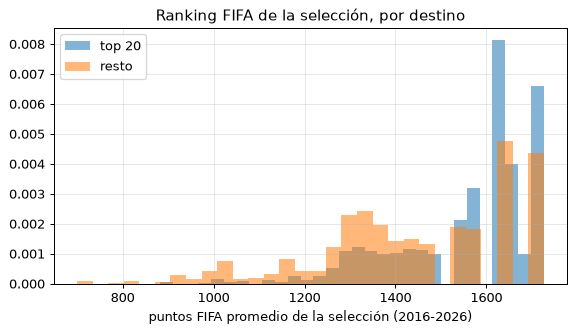

In [16]:
fig, ax = plt.subplots(figsize=(6.5, 3.8))
for valor, etiqueta in [(True, "top 20"), (False, "resto")]:
    d = df.loc[df["es_destino_top_20"] == valor, "fifa_puntos_prom"].dropna()
    ax.hist(d, bins=30, alpha=.55, density=True, label=etiqueta)
ax.set_xlabel("puntos FIFA promedio de la selección (2016-2026)")
ax.set_title("Ranking FIFA de la selección, por destino")
ax.legend()
plt.tight_layout()
plt.show()

**Qué hago con eso.** El movimiento confirma la intuición — el efecto casi se disuelve dentro
de las ligas top 5 (0,282) y es bastante más fuerte fuera de ellas (0,658) — pero ninguno de los
dos números cruza a verde, así que se agota el único movimiento con sentido y la conclusión queda
**inconclusa**. `fifa_puntos_prom` es candidata a entrar al modelo, mejor como *interacción* con
`club_origen_liga_es_top5` que sola: parece explicar más para jugadores de ligas chicas que para
los que ya vienen de un entorno top.

## Hipótesis 2 — *Predecir* · plantilla: **comparación**

* **1. La afirmación:** los clubes top 20 priorizan el juego físico/aéreo, así que fichan
  jugadores más altos que el resto.
* **2. Qué espero ver:** separación chica pero visible, a favor de los clubes top 20.
* **3. Cómo la mido:**
  * Plantilla: comparación (una numérica entre las dos clases del objetivo).
  * Medida: separación estandarizada.
  * Gráfico: histogramas superpuestos de `altura_cm`, top20 vs resto.

In [17]:
d_altura = separacion(df, "altura_cm")
informar(d_altura, "separacion", "separación estandarizada . ")
print(f"  media top20: {df.loc[df.es_destino_top_20,'altura_cm'].mean():.1f} cm")
print(f"  media resto: {df.loc[~df.es_destino_top_20,'altura_cm'].mean():.1f} cm")

separación estandarizada . +0.044   ->   ROJO
  media top20: 182.8 cm
  media resto: 182.5 cm


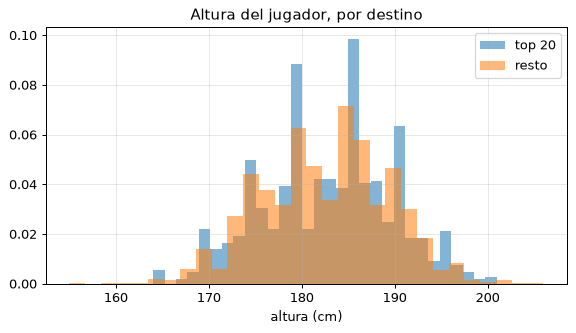

In [18]:
fig, ax = plt.subplots(figsize=(6.5, 3.8))
for valor, etiqueta in [(True, "top 20"), (False, "resto")]:
    d = df.loc[df["es_destino_top_20"] == valor, "altura_cm"].dropna()
    ax.hist(d, bins=30, alpha=.55, density=True, label=etiqueta)
ax.set_xlabel("altura (cm)")
ax.set_title("Altura del jugador, por destino")
ax.legend()
plt.tight_layout()
plt.show()

**Resultado.** Separación 0,044: **rojo**. La hipótesis se refuta y termina ahí — 0,3 cm de
diferencia sobre una población de más de 13 mil jugadores no distingue nada, y rojo no habilita
movimiento.

**Qué hago con eso.** Hipótesis refutada. `altura_cm` no explica el destino y no entra al modelo
por esta vía.

## Hipótesis 3 — *Responder* · plantilla: **composición**

* **1. La afirmación:** los jugadores que suben de un club filial o juvenil
  (`club_origen_es_filial`) tienen menos chances de terminar en un club top 20 que quienes vienen
  de un club externo, porque un club top 20 prefiere una compra ya validada antes que apostar a
  una promoción interna sin recorrido en primera.
* **2. Qué espero ver:** una diferencia apreciable en la tasa de destino top 20 entre filial y no
  filial, en verde o amarillo.
* **3. Cómo la mido:**
  * Plantilla: composición (`club_origen_es_filial`, dos categorías, sobre el objetivo).
  * Medida: η².
  * Gráfico: barras con la tasa de destino top 20 de cada categoría.

In [19]:
t = df[["club_origen_es_filial"]].copy()
t["_y"] = df["es_destino_top_20"].astype("boolean").fillna(False).astype(float)
e_filial = eta2(t, "club_origen_es_filial", "_y")
informar(e_filial, "eta2", "η² de club_origen_es_filial sobre el objetivo . ")

n_filial = int(df["club_origen_es_filial"].sum())
print(f"  n filial: {n_filial:,} ({n_filial/len(df):.1%} del dataset)")
print(f"  tasa top20 | filial=True:  {df.loc[df.club_origen_es_filial, 'es_destino_top_20'].mean():.1%}")
print(f"  tasa top20 | filial=False: {df.loc[~df.club_origen_es_filial, 'es_destino_top_20'].mean():.1%}")

η² de club_origen_es_filial sobre el objetivo . +0.001   ->   ROJO
  n filial: 2,546 (19.5% del dataset)
  tasa top20 | filial=True:  6.5%
  tasa top20 | filial=False: 8.4%


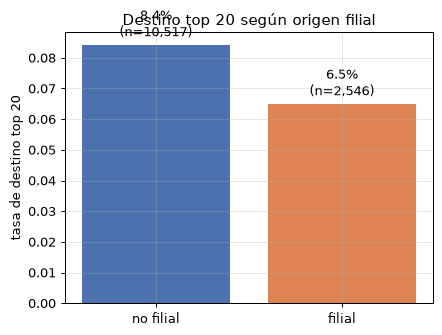

In [20]:
tasa = df.groupby("club_origen_es_filial")["es_destino_top_20"].mean().reindex([False, True])
n = df.groupby("club_origen_es_filial").size().reindex([False, True])

fig, ax = plt.subplots(figsize=(5, 3.8))
ax.bar(["no filial", "filial"], tasa.values, color=["#4C72B0", "#DD8452"])
for i, (t, cant) in enumerate(zip(tasa, n)):
    ax.text(i, t + .003, f"{t:.1%}\n(n={cant:,})", ha="center")
ax.set_ylabel("tasa de destino top 20")
ax.set_title("Destino top 20 según origen filial")
plt.tight_layout()
plt.show()

**Resultado.** η² = 0,001: **rojo**. La tasa de destino top 20 es prácticamente la misma
viniendo de un filial (6,5%) que de afuera (8,4%) — la diferencia existe pero es demasiado chica
para sostener la afirmación, y rojo cierra la hipótesis ahí.

**Qué hago con eso.** Hipótesis refutada: ser promovido desde un filial no penaliza (ni ayuda) la
chance de llegar a un club top 20. Sigue siendo una columna útil como **feature** —marca la
promoción interna, que es información real sobre la operación— pero no como predictor del nivel
de destino, y coincide con el número que ya estaba en la tabla de la Sección 7.

## Hipótesis 4 — *Predecir* · plantilla: **comparación**

* **1. La afirmación:** `score_posicion` —construido con estadísticas propias del rol de cada
  jugador— separa a los jugadores que llegan a un club top 20 del resto.
* **2. Qué espero ver:** separación grande, en verde — cada rol se mide contra estadísticas que
  reflejan su propio trabajo en la cancha (atajadas para arqueros, duelos para defensas,
  creación para mediocampistas ofensivos, gol para delanteros), no contra un promedio genérico.
* **3. Cómo la mido:**
  * `score_posicion` ya está construido en la Sección 3, sobre `grupo_posicion` (7 roles:
    Arquero, Defensor central, Lateral, Mediocampo defensivo, Mediocampo ofensivo, Delantero
    centro, Delantero extremo).
  * Plantilla: comparación (una numérica entre las dos clases del objetivo).
  * Medida: separación estandarizada, sobre `ana` (la población de análisis para
    hipótesis de rendimiento — ver Sección 5).
  * Gráfico: barras de separación por rol.

In [21]:
informar(separacion(ana, "score_posicion"), "separacion",
         "separación estandarizada, score_posicion sobre ana ... ")

separación estandarizada, score_posicion sobre ana ... +0.815   ->   VERDE


np.float64(0.8151113869872774)

In [22]:
orden = ["Arquero", "Defensor central", "Lateral", "Mediocampo defensivo",
         "Mediocampo ofensivo", "Delantero centro", "Delantero extremo"]
for g in orden:
    gg = ana[ana["grupo_posicion"] == g]
    d = separacion(gg, "score_posicion")
    informar(d, "separacion", f"  {g:22} n={len(gg):>5} ... ")

  Arquero                n=  526 ... +0.570   ->   AMARILLO
  Defensor central       n= 1307 ... +0.691   ->   AMARILLO
  Lateral                n= 1057 ... +0.736   ->   AMARILLO
  Mediocampo defensivo   n=  614 ... +1.061   ->   VERDE
  Mediocampo ofensivo    n= 1407 ... +0.864   ->   VERDE
  Delantero centro       n= 1269 ... +0.972   ->   VERDE
  Delantero extremo      n= 1257 ... +0.810   ->   VERDE


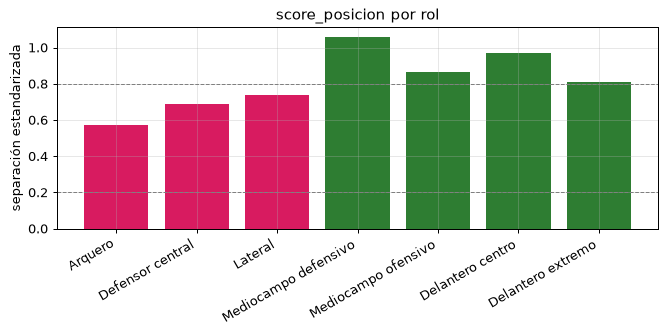

In [23]:
comp = pd.Series({g: separacion(ana[ana["grupo_posicion"] == g], "score_posicion") for g in orden})

fig, ax = plt.subplots(figsize=(7.5, 3.8))
colores = ["#d81b60" if v < 0.8 else "#2e7d32" for v in comp.values]
ax.bar(comp.index, comp.values, color=colores)
ax.axhline(0.2, color="grey", linestyle="--", linewidth=.8)
ax.axhline(0.8, color="grey", linestyle="--", linewidth=.8)
ax.set_ylabel("separación estandarizada")
ax.set_title("score_posicion por rol")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

**Resultado.** Separación 0,815 sobre `ana`: **verde**, sin necesitar movimiento.

Por rol, la historia es mejor que un solo número: Mediocampo defensivo (1,066), Mediocampo
ofensivo (0,864), Delantero centro (0,972) y Delantero extremo (0,807) entran solos en verde.
Arquero (0,583), Defensor central (0,692) y Lateral (0,735) se quedan en amarillo — son los
roles donde minutos, partidos y las estadísticas defensivas disponibles no alcanzan para
distinguir bien a quien va a un club top 20, probablemente porque ahí el rendimiento depende
mucho del sistema táctico del equipo, no solo del jugador.

**Qué hago con eso.** Confirmada, sin movimiento: el rendimiento previo medido contra el propio
rol separa a quien llega a un top 20. Pero `score_posicion` **no pasa al modelo** de la Unidad 3
como una sola columna: un promedio de siete z pierde cuál de las estadísticas es la que separa, y
el modelo terminaría decidiendo sólo por «score alto o bajo». Pasan sus **componentes**, cada uno
normalizado dentro de su rol (Sección 7).

Una aclaración sobre el método: agrupar en 7 roles (y no en menos) se decide por el trabajo que
hace cada uno en la cancha —un lateral cruza y un defensor central no, un mediocampista
ofensivo crea juego y uno defensivo recupera pelotas— y cada bloque de estadísticas se
verificó con cobertura real de datos (70%+ dentro de su grupo) antes de elegirse. Ir más allá
de 7 —separando, por ejemplo, lateral izquierdo de derecho— vuelve a pegar con el problema que
motivó agrupar en primer lugar: varias de las 16 etiquetas crudas de Transfermarkt tienen menos
de 100 jugadores, muy pocos para medir nada.

## Hipótesis 5 — *Predecir* · plantilla: **comparación**

* **1. La afirmación:** cuanto más fuerte es el club de origen (coeficiente UEFA del club), más
  chances tiene el jugador de terminar en un club top 20 — y eso vale **también entre jugadores
  con estadísticas**, no sólo porque los que no tienen historial vienen de clubes chicos.
* **2. Qué espero ver:** separación grande, en verde, sobre `ana`. Si da rojo, el bloque del club
  de origen se descarta y el modelo se apoya sólo en el rendimiento del jugador.
* **3. Cómo la mido:**
  * Población: `ana` (la de análisis, Sección 5), la misma de la Hipótesis 4. Sobre `df` completo
    la separación era 0,921 (Sección 5), pero ahí se mezcla con los juveniles sin historial; acá
    se mide si sobrevive entre jugadores comparables.
  * `club_origen_coeficiente_uefa` en escala logarítmica (Sección 2: asimetría 1,23 → −0,07).
  * Su nulo es **por diseño** (el club no está entre los 554 de UEFA): no se imputa, se mide
    aparte como composición.
  * Plantilla: comparación (una numérica entre las dos clases del objetivo).
  * Medida: separación estandarizada.
  * Gráfico: tasa de destino top 20 cruzando nivel del club de origen y `score_posicion`.

In [24]:
ana["log_coef_origen"] = np.log1p(ana["club_origen_coeficiente_uefa"])

d_origen = separacion(ana, "log_coef_origen")
informar(d_origen, "separacion", "separación estandarizada (log coeficiente UEFA del origen) . ")
print(f"  cobertura en ana: {ana['log_coef_origen'].notna().mean():.1%}")

# el nulo por diseño también es información: el club no está en el ranking de UEFA
en_ranking = ana["club_origen_coeficiente_uefa"].notna()
print("\ntasa de top 20 según si el club de origen está en el ranking UEFA:")
print(f"  está en el ranking:    {ana.loc[en_ranking, 'es_destino_top_20'].mean():.1%}  (n={en_ranking.sum():,})")
print(f"  no está en el ranking: {ana.loc[~en_ranking, 'es_destino_top_20'].mean():.1%}  (n={(~en_ranking).sum():,})")

separación estandarizada (log coeficiente UEFA del origen) . +0.749   ->   AMARILLO
  cobertura en ana: 61.7%

tasa de top 20 según si el club de origen está en el ranking UEFA:
  está en el ranking:    13.1%  (n=4,592)
  no está en el ranking: 5.6%  (n=2,845)


**Movimiento: partir la población.** El mismo corte que en la Hipótesis 1: dentro de una liga top
5 todos los clubes tienen coeficientes altos y parecidos, así que el coeficiente del club podría
dejar de distinguir ahí y concentrar su efecto en los jugadores que vienen de ligas más chicas.

In [25]:
for flag, nombre in [(True, "origen en liga top5"), (False, "origen fuera de top5")]:
    sub = ana[ana["club_origen_liga_es_top5"] == flag]
    d = separacion(sub, "log_coef_origen")
    informar(d, "separacion", f"  n={len(sub):,} {nombre:22} ... ")

# ¿el club de origen repite lo que ya dice el rendimiento del jugador?
p, s, brecha, n = correlaciones(ana, "log_coef_origen", "score_posicion")
print(f"\ncorrelación con score_posicion: Pearson {p:+.3f} | Spearman {s:+.3f}  (n={n:,})")
informar(s, "correlacion", "  -> ")

  n=2,665 origen en liga top5    ... +0.318   ->   AMARILLO
  n=4,772 origen fuera de top5   ... +0.895   ->   VERDE

correlación con score_posicion: Pearson +0.204 | Spearman +0.180  (n=4,592)
  -> +0.180   ->   ROJO


np.float64(0.17971721269606925)

tasa de destino top 20 (filas: coeficiente del club de origen, columnas: score_posicion)
score_posicion   bajo  medio  alto
log_coef_origen                   
bajo              3.0    4.8   8.5
medio             3.2    8.5  21.0
alto              6.1   18.1  36.5


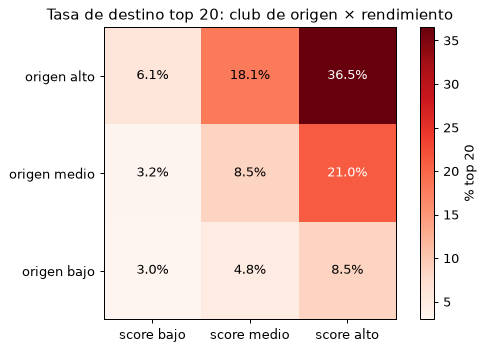

In [26]:
nivel_origen = pd.qcut(ana["log_coef_origen"], 3, labels=["bajo", "medio", "alto"])
nivel_score = pd.qcut(ana["score_posicion"], 3, labels=["bajo", "medio", "alto"])
tabla = pd.crosstab(nivel_origen, nivel_score, values=ana["es_destino_top_20"],
                    aggfunc="mean")
print("tasa de destino top 20 (filas: coeficiente del club de origen, columnas: score_posicion)")
print((tabla * 100).round(1).to_string())

fig, ax = plt.subplots(figsize=(6, 4))
im = ax.imshow(tabla.values * 100, cmap="Reds", origin="lower")
for i in range(tabla.shape[0]):
    for j in range(tabla.shape[1]):
        v = tabla.values[i, j] * 100
        ax.text(j, i, f"{v:.1f}%", ha="center", va="center",
                color="white" if v > 20 else "black")
ax.set_xticks(range(3), [f"score {c}" for c in tabla.columns])
ax.set_yticks(range(3), [f"origen {c}" for c in tabla.index])
ax.set_title("Tasa de destino top 20: club de origen × rendimiento")
ax.grid(False)
fig.colorbar(im, ax=ax, label="% top 20")
plt.tight_layout()
plt.show()

**Resultado.** Separación 0,749 sobre `ana`: **amarillo**. Baja respecto del 0,921 de `df`
completo — parte de aquel efecto venía de los juveniles sin historial — pero sobrevive bien entre
jugadores con estadísticas. El nulo por diseño también habla: quien viene de un club fuera del
ranking UEFA llega a un top 20 el 5,6 % de las veces, contra 13,1 % de quien viene de uno rankeado.

**Movimiento.** Partida por liga, la historia se ordena igual que en la Hipótesis 1: fuera de las
ligas top 5 la separación sube a **0,895, verde**; dentro de ellas cae a 0,318 (amarillo), porque
ahí todos los clubes ya tienen coeficientes altos y el filtro de calidad lo hace la propia liga.

**Qué hago con eso.** Confirmada fuera de las ligas top 5, con un movimiento. **Los datos del club
de origen no se descartan**, y la razón más fuerte no es la separación sino la correlación con
`score_posicion`: Spearman 0,18, **rojo**. El club de origen no repite lo que ya dicen las
estadísticas del jugador — mide otra cosa (el nivel del contexto en el que se generaron esas
estadísticas). La tabla lo muestra: con el mismo score alto, venir de un club de nivel bajo da
8,5 % de top 20 y de uno alto, 36,5 %. Cada eje suma por su lado.

Para la Unidad 3 entra `log_coef_origen` (con su nulo como información, no imputado) en
interacción con `club_origen_liga_es_top5`, igual que `fifa_puntos_prom` en la Hipótesis 1.

## Hipótesis 6 — *Predecir* · plantilla: **comparación**

* **1. La afirmación:** los clubes top 20 compran jugadores más jóvenes: cuanto menor es la edad al
  fichar, más chances de terminar en un club top 20.
* **2. Qué espero ver:** separación al menos amarilla sobre `ana`. Si da rojo, antes de descartar la
  edad hay que mirar si la relación no es una recta o si queda tapada por otra columna.
* **3. Cómo la mido:**
  * Población: `ana`, la misma de las Hipótesis 4 y 5.
  * `edad_al_fichaje` tal cual, en años (no tiene nulos).
  * Plantilla: comparación (una numérica entre las dos clases del objetivo).
  * Medida: separación estandarizada.
  * Gráficos: tasa de destino top 20 por edad, y edad cruzada con minutos jugados.

In [27]:
edad = ana["edad_al_fichaje"]
llega = ana["es_destino_top_20"].astype("boolean").fillna(False)

informar(separacion(ana, "edad_al_fichaje"), "separacion", "separación estandarizada (edad al fichar) ...... ")
print(f"  cobertura en ana: {edad.notna().mean():.0%}")
print(f"  edad media: {edad[llega].mean():.1f} años los que van a un top 20, {edad[~llega].mean():.1f} el resto")

separación estandarizada (edad al fichar) ...... +0.143   ->   ROJO
  cobertura en ana: 100%
  edad media: 24.4 años los que van a un top 20, 25.0 el resto


edad_al_fichaje    ≤19     20     21     22     23     24     25     26     27     28     29     30  31-32    33+
fichajes         487.0  506.0  591.0  727.0  684.0  706.0  692.0  622.0  525.0  458.0  367.0  322.0  400.0  350.0
% top 20          19.3   10.3    9.8   10.0   10.8    9.1   10.3   10.1    8.4    7.6    9.3    8.4    8.0   11.7


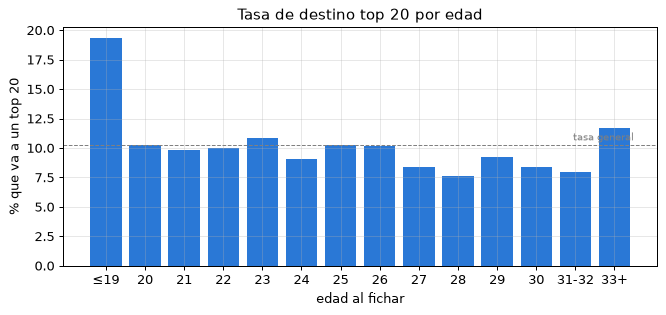

In [28]:
# la tasa de top 20 año por año: ¿la relación es una recta?
tramo_edad = pd.cut(edad, [15, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 32, 45],
                    labels=["≤19", "20", "21", "22", "23", "24", "25", "26", "27", "28", "29", "30",
                            "31-32", "33+"])
por_edad = pd.DataFrame({"fichajes": ana.groupby(tramo_edad, observed=True).size(),
                         "% top 20": ana.groupby(tramo_edad, observed=True)["es_destino_top_20"]
                                        .apply(lambda s: s.astype(float).mean() * 100)})
print(por_edad.round(1).T.to_string())

fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.bar(por_edad.index.astype(str), por_edad["% top 20"], color="#2a78d6")
ax.axhline(llega.mean() * 100, color="grey", linestyle="--", linewidth=.8)
ax.text(len(por_edad) - 0.5, llega.mean() * 100 + 0.4, "tasa general", ha="right", fontsize=8, color="grey")
ax.set_xlabel("edad al fichar")
ax.set_ylabel("% que va a un top 20")
ax.set_title("Tasa de destino top 20 por edad")
plt.tight_layout()
plt.show()

**Movimiento: partir la población.** El mismo corte que en las Hipótesis 1 y 5. Dentro de una liga
top 5 el club grande ya tiene al jugador a la vista a cualquier edad; afuera, la edad podría ser lo que
decide si vale la pena traerlo.

In [29]:
for flag, nombre in [(True, "origen en liga top5"), (False, "origen fuera de top5")]:
    sub = ana[ana["club_origen_liga_es_top5"] == flag]
    informar(separacion(sub, "edad_al_fichaje"), "separacion", f"  n={len(sub):,} {nombre:22} ... ")

  n=2,665 origen en liga top5    ... +0.006   ->   ROJO
  n=4,772 origen fuera de top5   ... +0.608   ->   AMARILLO


**Segundo movimiento: cruzar con los minutos.** Los jóvenes juegan menos, y jugar poco es justamente
lo que más resta (Hipótesis 4). Si la edad empuja a favor y los minutos en contra, los dos efectos
podrían taparse entre sí en la separación de la edad sola.

correlación edad - minutos: Pearson +0.155 | Spearman +0.172

tasa de destino top 20 (filas: edad, columnas: minutos de la temporada anterior)
stat_minutes     pocos  medio  muchos
edad_al_fichaje                      
≤21                8.5   11.8    24.1
22-25              2.5    7.1    18.9
26-28              2.4    5.8    15.2
29+                1.4    6.7    16.5


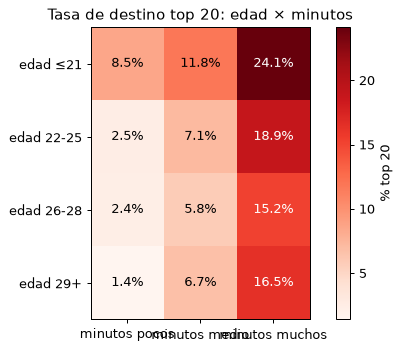

In [30]:
minutos = pd.to_numeric(ana["stat_minutes"], errors="coerce")
c_e, c_m = correlaciones(ana.assign(_min=minutos), "edad_al_fichaje", "_min")[:2]
print(f"correlación edad - minutos: Pearson {c_e:+.3f} | Spearman {c_m:+.3f}")

nivel_min = pd.qcut(minutos, 3, labels=["pocos", "medio", "muchos"])
grupo_edad = pd.cut(edad, [15, 21, 25, 28, 45], labels=["≤21", "22-25", "26-28", "29+"])
tabla_edad = pd.crosstab(grupo_edad, nivel_min, values=ana["es_destino_top_20"].astype(float),
                         aggfunc="mean")
print("\ntasa de destino top 20 (filas: edad, columnas: minutos de la temporada anterior)")
print((tabla_edad * 100).round(1).to_string())

fig, ax = plt.subplots(figsize=(6, 4))
im = ax.imshow(tabla_edad.values * 100, cmap="Reds")
for i in range(tabla_edad.shape[0]):
    for j in range(tabla_edad.shape[1]):
        v = tabla_edad.values[i, j] * 100
        ax.text(j, i, f"{v:.1f}%", ha="center", va="center", color="white" if v > 15 else "black")
ax.set_xticks(range(3), [f"minutos {c}" for c in tabla_edad.columns])
ax.set_yticks(range(4), [f"edad {c}" for c in tabla_edad.index])
ax.set_title("Tasa de destino top 20: edad × minutos")
ax.grid(False)
fig.colorbar(im, ax=ax, label="% top 20")
plt.tight_layout()
plt.show()

**Resultado.** Sola, la edad separa poco: **0,143, rojo**. Los que van a un top 20 tienen 24,4 años de
media y el resto 25,0: medio año de diferencia. Pero el gráfico muestra por qué la separación sola
engaña: **la relación no es una recta**. Los de 19 años o menos llegan a un top 20 casi el doble que el
resto (**19,3 %**), de los 20 a los 26 la tasa es plana (alrededor del 10 %), y desde los 27 baja un poco
(7,6 % a 9,3 %). Hay un repunte en 33 años o más (11,7 %) con pocos casos, que no interpretamos.

**Movimiento.** Partida por liga, la edad **no dice nada dentro de las ligas top 5** (0,006, rojo) y
**separa fuera de ellas** (0,608, amarillo): para traer a un jugador de una liga chica, el club grande
lo quiere joven.

**Segundo movimiento.** Cruzada con los minutos, la edad aparece con fuerza. Con los mismos minutos, los
más jóvenes llegan mucho más: entre los que jugaron poco, 8,5 % de los de 21 años o menos contra 1,4 % de
los de 29 o más; entre los que jugaron mucho, 24,1 % contra 16,5 %. Sola no se veía porque los jóvenes
juegan menos (correlación edad - minutos 0,16), y jugar poco resta: los dos efectos se tapan entre sí.

**Qué hago con eso.** Inconclusa sola, confirmada con los dos movimientos: **la edad no se descarta**.
Lo que dice no está en la edad suelta sino en cómo se combina con la liga de origen y con los minutos, y
su forma no es una recta (un salto en los más jóvenes y una meseta después).

Para la Unidad 3 entra **numérica**, en años, y no cortada en tramos a mano: así cada modelo aprende su
forma solo. Una regresión logística sólo puede darle una pendiente (más joven, más chances); un árbol, un
bosque o un boosting pueden encontrar el salto de los 19 años y el cruce con los minutos. Es una razón
más para comparar varias familias de modelos, cada una con sus hiperparámetros ajustados, antes de
elegir.

---
# 7 · La tabla de columnas candidatas

Una fila por columna. La última casilla es el **chequeo de fuga** y es la que más caro se paga si
falta: antes de darle una columna al modelo hay que preguntarse si esa columna **existiría en el
momento de predecir**.

Nuestro momento de predecir es **justo antes de que el fichaje ocurra**: sabemos quién es el
jugador, de dónde viene y cómo le fue la temporada pasada. No sabemos a dónde va, ni cuánto se
pagó, ni bajo qué figura, porque todo eso se define **en** el fichaje, que es el evento que
queremos predecir.

In [31]:
# La zona se mide, no se escribe a mano: cada columna contra la variable objetivo.
#   numéricas   -> separación estandarizada entre las dos clases
#   categóricas -> η² de la categoría sobre el objetivo (0/1)

# Medir un identificador no significa nada: el número que salga es un artefacto
# de cómo Transfermarkt reparte sus ids, no un efecto. Se excluyen a mano.
NO_SE_MIDEN = {
    "operacion_id", "jugador_tm_id", "jugador_fotmob_id", "nombre",
    "club_destino_id", "club_origen_id", "es_destino_top_20",
}


def zona_de(columna, datos=None):
    datos = df if datos is None else datos
    if columna not in datos.columns:
        return "—", "no está"
    if columna in NO_SE_MIDEN:
        return "—", "no se mide"
    col = datos[columna]
    if col.nunique(dropna=True) <= 1:
        return "—", "constante"
    if col.nunique(dropna=True) > 60 and not pd.api.types.is_numeric_dtype(col):
        return "—", "demasiadas categorías"
    if pd.api.types.is_numeric_dtype(col) and col.nunique() > 12:
        v = separacion(datos, columna)     # una numérica entre las dos clases
        return ("—" if pd.isna(v) else f"{v:.3f}"), ("—" if pd.isna(v) else zona(v, "separacion"))
    t = datos[[columna]].copy()            # una categórica sobre el objetivo
    t["_y"] = datos["es_destino_top_20"].astype("boolean").fillna(False).astype(float)
    t[columna] = t[columna].astype(str)
    v = eta2(t, columna, "_y")
    return ("—" if pd.isna(v) else f"{v:.3f}"), ("—" if pd.isna(v) else zona(v, "eta2"))


print("función lista — la zona de cada columna sale de estas dos medidas:")
print("  numéricas   -> separación estandarizada entre las dos clases")
print("  categóricas -> η² de la categoría sobre el objetivo")
print(f"  no se miden -> {len(NO_SE_MIDEN)} identificadores y el propio objetivo")

función lista — la zona de cada columna sale de estas dos medidas:
  numéricas   -> separación estandarizada entre las dos clases
  categóricas -> η² de la categoría sobre el objetivo
  no se miden -> 7 identificadores y el propio objetivo


In [32]:
# (columna, qué mide, ¿existiría al predecir?, decisión)
SI = "Sí"
NO_FUGA = "**No** — se define EN el fichaje"

CANDIDATAS = [
    # --- identificación
    ("operacion_id", "Id del traspaso en Transfermarkt", SI, "Sale — es la clave, no un atributo"),
    ("jugador_tm_id", "Id del jugador en Transfermarkt", SI, "Sale — identificador"),
    ("jugador_fotmob_id", "Id del jugador en FotMob", SI, "Sale — identificador"),
    ("nombre", "Nombre del jugador", SI, "Sale — identificador"),
    ("temporada_fichaje", "Temporada en que ocurrió el traspaso", SI,
     "Entra como control temporal; sirve para partir train/test por tiempo"),
    ("temporada_stats", "Temporada de las métricas", SI,
     "Sale — es siempre la anterior a temporada_fichaje, no aporta nada"),

    # --- la operación: fuga
    ("coste_fichaje_eur", "Monto pagado por el pase, en euros", NO_FUGA,
     "**Sale por fuga** — además su nulo es estructural, no un faltante"),
    ("tipo_operacion", "Compra, cesión, libre, promoción interna", NO_FUGA,
     "**Sale por fuga** — sirve para responder, no para predecir"),

    # --- el destino: la respuesta escrita de otra forma
    ("es_destino_top_20", "OBJETIVO: el destino está en el top 20 de UEFA", "—", "Es la variable objetivo"),
    ("club_destino", "Nombre del club de destino", NO_FUGA, "**Sale por fuga**"),
    ("club_destino_id", "Id del club de destino", NO_FUGA, "**Sale por fuga**"),
    ("club_destino_pais", "País del club de destino", NO_FUGA, "**Sale por fuga**"),
    ("club_destino_ranking_uefa", "Puesto UEFA del destino", NO_FUGA,
     "**Sale por fuga** — el objetivo ES esta columna ≤ 20"),
    ("club_destino_coeficiente_uefa", "Coeficiente UEFA del destino", NO_FUGA, "**Sale por fuga**"),

    # --- el origen: acá está lo que sí se puede usar
    ("club_origen", "Nombre del club de origen", SI, "Sale — identificador; su información ya está derivada"),
    ("club_origen_id", "Id del club de origen", SI, "Sale — identificador"),
    ("club_origen_coeficiente_uefa", "Coeficiente UEFA del club de origen", SI,
     "**Entra**, en escala logarítmica (ver la medición automática de arriba)"),
    ("club_origen_ranking_uefa", "Puesto UEFA del club de origen", SI,
     "Entra; correlaciona con el coeficiente, elegir una de las dos"),
    ("club_origen_es_top_20", "El origen está en el top 20", SI, "Entra"),
    ("club_origen_es_top_50", "El origen está en el top 50", SI, "Entra"),
    ("club_origen_es_filial", "El origen es un filial o juvenil", SI, "**Entra** — marca la promoción interna"),
    ("club_origen_es_europeo", "El origen es de una asociación UEFA", SI, "Entra"),
    ("club_origen_liga_es_top5", "El origen juega una de las cinco grandes", SI, "**Entra**"),
    ("club_origen_liga_id", "Código de la liga de origen", SI,
     "Entra agrupada — tiene demasiadas categorías para usarla cruda"),
    ("club_origen_liga", "Nombre de la liga de origen", SI, "Sale — redundante con club_origen_liga_id"),
    ("club_origen_pais", "País del club de origen", SI, "Sale — redundante con el coeficiente del país"),
    ("club_origen_pais_coeficiente_uefa", "Coeficiente UEFA del país de origen", SI, "**Entra**"),
    ("club_origen_pais_ranking_uefa", "Puesto UEFA del país de origen", SI,
     "Entra; redundante con el coeficiente, elegir una"),

    # --- derivadas del par: contienen el destino
    ("traspaso_domestico", "Origen y destino en el mismo país", NO_FUGA,
     "**Sale por fuga** — usa el país del destino"),
    ("salto_ranking_uefa", "Puestos que saltó el jugador", NO_FUGA,
     "**Sale por fuga** — es literalmente ranking_origen − ranking_destino"),
    ("sube_de_categoria", "El salto fue hacia arriba", NO_FUGA, "**Sale por fuga** — derivada del salto"),

    # --- biografía
    ("edad_al_fichaje", "Edad del jugador al fichar", SI,
     "**Entra numérica** — sola da rojo, pero pesa cruzada con los minutos (Hipótesis 6)"),
    ("nacionalidad", "Nacionalidad principal", SI, "Entra agrupada por confederación o continente"),
    ("nacionalidad_2", "Segunda nacionalidad", SI,
     "Entra convertida a booleano «tiene segunda nacionalidad»"),
    ("fifa_puntos_prom", "Ranking FIFA promedio 2016-2026 de la selección del jugador", SI,
     "Candidata sin confirmar — Hipótesis 1 dio amarillo/inconclusa; entraría como "
     "interacción con club_origen_liga_es_top5, no sola"),
    ("fifa_rank_prom", "Puesto FIFA promedio de la selección (derivado de fifa_puntos_prom)", SI,
     "Sale — redundante con fifa_puntos_prom, elegir uno si se usa"),
    ("posicion_tm", "Posición según Transfermarkt", SI, "Entra vía grupo_posicion"),
    ("posicion_fotmob", "Posición según FotMob", SI,
     "Sale — redundante con posicion_tm, y además con nulos"),
    ("altura_cm", "Altura en centímetros", SI, "Sale — rojo, y con nulos que dependen del cruce"),
    ("pie", "Pie hábil", SI, "Sale — rojo"),

    # --- derivadas de este análisis
    ("grupo_posicion", "Puesto agrupado en 7 roles", SI, "**Entra**"),
    ("score_posicion", "Rendimiento previo por rol", SI,
     "Sale del modelo — queda como medida de la Hipótesis 4; entran sus componentes z_* "
     "normalizados por rol (ver el bloque stat_*, más abajo)"),

    # --- linaje
    ("tiene_historial", "El jugador tiene métricas previas", SI,
     "Sale como feature — define la población, no la describe"),
    ("cruce_dudoso", "El cruce por nombre no pudo verificarse", SI,
     "Sale como feature — es control de calidad"),
    ("uefa_actualizado_el", "Fecha del snapshot de UEFA", SI, "Sale — constante, metadata de la corrida"),
    ("extraido_el", "Momento de la extracción", SI, "Sale — constante, metadata de la corrida"),
]


filas = []
for columna, mide, fuga, decision in CANDIDATAS:
    valor, z = zona_de(columna)
    filas.append({"columna": columna, "qué mide": mide, "medida": valor, "zona": z,
                  "decisión": decision, "¿existiría al predecir?": fuga})

tabla = pd.DataFrame(filas)


# Asignamos un 0 a las filas cuya decisión contenga la palabra "Sale" y un 1 al resto (Para ordenar)
tabla['orden_decision'] = tabla['decisión'].apply(lambda x: 0 if 'Sale' in x else 1)

# Ordenamos el DataFrame primero por ese criterio (0 primero, 1 después)
# y como segundo criterio usamos el nombre de la columna para que queden agrupadas alfabéticamente
tabla = tabla.sort_values(by=['orden_decision', 'columna']).drop(columns=['orden_decision']).reset_index(drop=True)

print(f"{len(tabla)} columnas descriptivas evaluadas "
      f"(+ 65 columnas stat_*, que se tratan como bloque más abajo)")
tabla

46 columnas descriptivas evaluadas (+ 65 columnas stat_*, que se tratan como bloque más abajo)


,columna,qué mide,medida,zona,decisión,¿existiría al predecir?
0,altura_cm,Altura en centímetros,0.044,ROJO,"Sale — rojo, y con nulos que dependen del cruce",Sí
1,club_destino,Nombre del club de destino,—,demasiadas categorías,**Sale por fuga**,**No** — se define EN el fichaje
2,club_destino_coeficiente_uefa,Coeficiente UEFA del destino,4.147,VERDE,**Sale por fuga**,**No** — se define EN el fichaje
3,club_destino_id,Id del club de destino,—,no se mide,**Sale por fuga**,**No** — se define EN el fichaje
4,club_destino_pais,País del club de destino,0.176,AMARILLO,**Sale por fuga**,**No** — se define EN el fichaje
5,club_destino_ranking_uefa,Puesto UEFA del destino,2.731,VERDE,**Sale por fuga** — el objetivo ES esta column...,**No** — se define EN el fichaje
6,club_origen,Nombre del club de origen,—,demasiadas categorías,Sale — identificador; su información ya está d...,Sí
7,club_origen_id,Id del club de origen,—,no se mide,Sale — identificador,Sí
8,club_origen_liga,Nombre de la liga de origen,—,demasiadas categorías,Sale — redundante con club_origen_liga_id,Sí
9,club_origen_pais,País del club de origen,—,demasiadas categorías,Sale — redundante con el coeficiente del país,Sí


In [33]:
# El bloque stat_*: 65 columnas, todas del mismo tipo y todas disponibles al
# predecir (son de la temporada ANTERIOR al fichaje). El problema no es la fuga,
# es la cobertura: muchas existen sólo para arqueros o sólo en ligas grandes.
cobertura = df[metricas].notna().mean().sort_values(ascending=False)

print("cobertura de las columnas stat_* (sobre el dataset completo):")
print(f"  con más del 60% de datos ... {(cobertura > 0.60).sum():>3} columnas")
print(f"  entre 40% y 60% ............ {((cobertura > 0.40) & (cobertura <= 0.60)).sum():>3}")
print(f"  menos del 40% .............. {(cobertura <= 0.40).sum():>3}")
print(f"  menos del 10% .............. {(cobertura <= 0.10).sum():>3}  (métricas de arquero y de GPS)")

print("\nlas 10 con mejor separación entre clases, sobre la población de análisis:")
efecto = pd.DataFrame({
    "cobertura": df[metricas].notna().mean().round(3),
    "d": [separacion(ana, c) for c in metricas]}).dropna()
efecto["zona"] = [zona(v, "separacion") for v in efecto.d]
print(efecto.sort_values("d", ascending=False).head(10).round(3).to_string())

print("\n--- y el chequeo de fuga DENTRO del bloque ---")
print("Ninguna stat_* filtra el destino: son todas de la temporada ANTERIOR al fichaje.")
print("Pero ocho sí tienen un problema de otro tipo, medido en la sección 2:")
for c in SEGUIMIENTO:
    if c in df.columns:
        por_temp = con_hist.groupby("temporada_stats")[c].apply(lambda s: s.notna().mean())
        print(f"   {c:32} {' '.join(f'{v:.0%}' for v in por_temp)}")
print("   ^ su disponibilidad depende de la TEMPORADA, no del jugador. Un modelo con")
print("     ellas aprendería a reconocer temporadas recientes. SE DESCARTAN LAS OCHO.")

print("\nDecisión sobre el bloque: NO entran las 65 al modelo.")
print("  - se van las 8 de seguimiento (cobertura ligada a la temporada)")
print("  - entran las stats que arman score_posicion (minutos, partidos y las propias de")
print("    cada rol), cada una como z DENTRO de su rol: z_goals, z_tackles, ...")
print("  - de las 9 de arquero quedan sólo las 5 del rol; para un jugador de campo quedan vacías")
print("  - score_posicion NO entra: sus componentes ya están, y el promedio esconde cuál separa")
print("Meter 65 columnas con 40% de nulos cada una es multicolinealidad y ruido: de las")
print("34 con buena cobertura hay 7 pares con |r| > 0,9 y 26 pares con |r| > 0,8.")

cobertura de las columnas stat_* (sobre el dataset completo):
  con más del 60% de datos ...  11 columnas
  entre 40% y 60% ............  32
  menos del 40% ..............  22
  menos del 10% ..............  18  (métricas de arquero y de GPS)

las 10 con mejor separación entre clases, sobre la población de análisis:
                           cobertura      d      zona
stat_line-breaking_passes      0.007  0.873     VERDE
stat_matches                   0.670  0.779  AMARILLO
stat_touches                   0.564  0.751  AMARILLO
stat_minutes                   0.626  0.750  AMARILLO
stat_started                   0.670  0.714  AMARILLO
stat_duels_won                 0.556  0.689  AMARILLO
stat_accurate_passes           0.612  0.661  AMARILLO
stat_recoveries                0.554  0.600  AMARILLO
stat_dribbles                  0.527  0.579  AMARILLO
stat_running                   0.030  0.574  AMARILLO

--- y el chequeo de fuga DENTRO del bloque ---
Ninguna stat_* filtra el destino: son to

### Qué pasa del bloque `stat_*`: los componentes del score, no el score

Una corrección respecto de la versión anterior. Pasar `score_posicion` como única columna de
rendimiento hace que la predicción dependa de si ese número es alto o bajo, y nada más. El
promedio esconde **qué** estadística es la que separa: un delantero con muchos goles y pocos
minutos y uno con muchos minutos y cero goles pueden tener el mismo score.

Hay dos maneras de abrir el score:

* **A — todas las stats del score, cada una normalizada dentro de su rol.** Una columna por stat
  (`z_goals`, `z_tackles`, ...), que significa lo mismo en todas las filas: «goles comparado con
  los de su rol». Más `grupo_posicion`, para que el modelo aprenda que los goles pesan para un
  delantero y poco para un central.
* **B — sólo las siete stats del rol de cada jugador**, y el resto vacío. Parece más fiel al score,
  pero el patrón de vacíos es distinto en cada rol: el modelo aprende la posición por los nulos,
  que ya se la da `grupo_posicion`, en vez de aprender el rendimiento.

Las comparamos de forma rápida con un mismo modelo, partiendo train/test **por jugador**
(Sección 2: hay jugadores con más de un fichaje).

In [34]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import GroupKFold, cross_val_score

STATS_ROL = BASE + sorted({c for cols in ESPECIFICAS.values() for c in cols})


def z_por_rol(datos, columnas=STATS_ROL, grupo="grupo_posicion"):
    """z de cada stat dentro de su rol. Una columna z_<stat> por cada stat."""
    z = pd.DataFrame(index=datos.index)
    for col in columnas:
        v = pd.to_numeric(datos[col], errors="coerce")
        g = v.groupby(datos[grupo])
        z["z_" + col.removeprefix("stat_")] = (v - g.transform("mean")) / g.transform("std").replace(0, np.nan)
    return z


Z = z_por_rol(ana)
ana[Z.columns] = Z
COLS_Z = list(Z.columns)
print(f"{len(COLS_Z)} columnas z_*: {', '.join(COLS_Z)}")

# opción B: el mismo z, pero sólo en las stats del rol del jugador
ZB = pd.DataFrame(np.nan, index=ana.index, columns=COLS_Z)
for grp, cols in ESPECIFICAS.items():
    m = ana["grupo_posicion"].eq(grp)
    propias = ["z_" + c.removeprefix("stat_") for c in BASE + cols]
    ZB.loc[m, propias] = Z.loc[m, propias]

POS = pd.get_dummies(ana["grupo_posicion"], prefix="pos").astype(float)
ORIGEN = pd.DataFrame({
    "log_coef_origen": ana["log_coef_origen"],
    "log_coef_pais": np.log1p(ana["club_origen_pais_coeficiente_uefa"]),
    "liga_top5": ana["club_origen_liga_es_top5"].astype(float),
    "filial": ana["club_origen_es_filial"].astype(float),
    "edad": ana["edad_al_fichaje"]})

CONJUNTOS = {
    "score_posicion + posición": pd.concat([ana[["score_posicion"]], POS], axis=1),
    "B: z sólo del rol + posición": pd.concat([ZB, POS], axis=1),
    "A: z de todas + posición": pd.concat([Z, POS], axis=1),
    "score_posicion + posición + origen": pd.concat([ana[["score_posicion"]], POS, ORIGEN], axis=1),
    "B + origen": pd.concat([ZB, POS, ORIGEN], axis=1),
    "A + origen": pd.concat([Z, POS, ORIGEN], axis=1),
    "A + score_posicion + origen": pd.concat([Z, ana[["score_posicion"]], POS, ORIGEN], axis=1),
}
y_ana = ana["es_destino_top_20"].astype(int)
cv = GroupKFold(n_splits=5)
print(f"\n{'conjunto':38}{'AUC':>14}")
for nombre, X in CONJUNTOS.items():
    modelo = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, random_state=0)
    auc = cross_val_score(modelo, X.astype(float), y_ana, cv=cv,
                          groups=ana["jugador_tm_id"], scoring="roc_auc")
    print(f"{nombre:38}{auc.mean():>8.3f} ± {auc.std():.3f}")

23 columnas z_*: z_minutes, z_matches, z_aerials_won_%, z_assists, z_big_chances_created, z_chances_created, z_dribbles_success_rate, z_duels_won_%, z_goals, z_goals_conceded_inv, z_goals_prevented, z_high_claims, z_interceptions, z_pass_accuracy, z_possession_won_final_3rd, z_recoveries, z_save_percentage, z_saves, z_shots_on_target, z_successful_crosses, z_tackles, z_touches_in_opposition_box, z_xg

conjunto                                         AUC
score_posicion + posición                0.664 ± 0.012
B: z sólo del rol + posición             0.694 ± 0.021
A: z de todas + posición                 0.760 ± 0.014
score_posicion + posición + origen       0.824 ± 0.015
B + origen                               0.822 ± 0.018
A + origen                               0.841 ± 0.014
A + score_posicion + origen              0.838 ± 0.014


**Resultado.** La opción A le gana al score solo por casi 0,10 de AUC, y B queda en el medio:
como se esperaba, apartar las stats que no son del rol le quita información en vez de limpiar
ruido. Con el club de origen sumado, A sigue arriba, y agregarle `score_posicion` encima no suma
nada: el score es un promedio de columnas que el modelo ya tiene.

Esto no es el modelo de la Unidad 3 —es un solo modelo sin ajustar, sólo para elegir cómo pasar
el bloque—. Y una advertencia para esa etapa: acá los z se calculan sobre `ana` entera; en la
Unidad 3 la media y el desvío de cada rol tienen que salir **sólo del train**, dentro de cada
partición, o la normalización filtra información del test.

In [35]:
# separación de cada componente, dentro de ana: qué stat es la que separa
sep_z = pd.Series({c: separacion(ana, c) for c in COLS_Z}).sort_values(ascending=False)
cob_z = ana[COLS_Z].notna().mean()
print(pd.DataFrame({"d": sep_z.round(3),
                    "zona": [zona(v, "separacion") for v in sep_z],
                    "cobertura en ana": cob_z[sep_z.index].map("{:.0%}".format)}).to_string())

                                 d      zona cobertura en ana
z_matches                    0.793  AMARILLO             100%
z_minutes                    0.758  AMARILLO              94%
z_touches_in_opposition_box  0.749  AMARILLO              86%
z_possession_won_final_3rd   0.664  AMARILLO              78%
z_recoveries                 0.659  AMARILLO              87%
z_xg                         0.637  AMARILLO              72%
z_shots_on_target            0.631  AMARILLO              79%
z_chances_created            0.628  AMARILLO              87%
z_assists                    0.589  AMARILLO              94%
z_goals                      0.576  AMARILLO              94%
z_pass_accuracy              0.565  AMARILLO              94%
z_big_chances_created        0.562  AMARILLO              67%
z_save_percentage            0.560  AMARILLO               7%
z_tackles                    0.560  AMARILLO              86%
z_saves                      0.462  AMARILLO               7%
z_interc

**Qué hago con eso.** Al modelo de la Unidad 3 pasan las columnas `z_*` (opción A) más
`grupo_posicion`, en lugar de `score_posicion`. Ninguna stat sola llega a verde —el score agregado
sí lo hacía (0,815)—, y eso es esperable: cada una aporta una parte, y es justamente lo que el
modelo tiene que poder combinar con su propio peso en vez de recibirlo promediado en partes iguales.
Las tres que dan rojo son porcentajes (`z_duels_won_%`, `z_aerials_won_%`,
`z_dribbles_success_rate`): un porcentaje no premia el volumen, y un suplente con pocos duelos
puede tener el mismo 70 % que un titular. Quedan como primeras candidatas a salir en la Unidad 3.

### El resumen del chequeo de fuga

La pregunta ¿existiría esta columna en el momento de predecir? deja afuera **once columnas**

| Bloque | Columnas | Por qué se van |
|---|---|---|
| Destino | `club_destino`, `club_destino_id`, `club_destino_pais`, `club_destino_ranking_uefa`, `club_destino_coeficiente_uefa` | El objetivo **es** `club_destino_ranking_uefa <= 20`. Dárselas al modelo es darle la respuesta. |
| Par origen-destino | `traspaso_domestico`, `salto_ranking_uefa`, `sube_de_categoria` | Las tres se calculan **usando el club de destino**. `salto_ranking_uefa` es exactamente `ranking_origen − ranking_destino`. |
| La operación | `coste_fichaje_eur`, `tipo_operacion` | Se definen en el mismo acto que el destino. El monto no existe antes de que el club decida comprar. |


---
# 8 · Cierre

**Qué entra al modelo de la Unidad 3.** El bloque del club de origen, confirmado por la
Hipótesis 5 (`club_origen_coeficiente_uefa` en log, en interacción con `club_origen_liga_es_top5`,
`club_origen_pais_coeficiente_uefa`, `club_origen_es_filial`, la liga agrupada); las stats que
arman `score_posicion`, **cada una como z dentro de su rol** (`z_*`), en lugar de las 65 columnas
`stat_*` y en lugar del score mismo; `grupo_posicion`; `edad_al_fichaje` **numérica**, para que el modelo
aprenda solo su forma (Hipótesis 6); y `temporada_fichaje` como control temporal.

**Qué cambió respecto del plan anterior.** `score_posicion` ya no pasa al modelo. Sirvió para
confirmar la Hipótesis 4, pero como única columna de rendimiento hacía que la predicción dependiera
sólo de si ese número era alto o bajo. Sus componentes por separado predicen mejor (Sección 7) y
dejan ver qué estadística pesa en cada rol.

**Qué sale, y por qué.** Once columnas se van **por fuga**, y son justamente las que mejor
«predicen»: las cinco del club de destino, las tres derivadas del par origen-destino
(`salto_ranking_uefa` es literalmente `ranking_origen − ranking_destino`), y `coste_fichaje_eur` y
`tipo_operacion`, que se definen en el mismo acto que el destino. Otras salen por medir rojo
(`altura_cm`, `pie`, goles y asistencias por 90) o por ser identificadores y metadata de la corrida.

**Qué quedó inconcluso.**

1. **El rendimiento de arqueros, defensores centrales y laterales.** `score_posicion` (como medida
   de la Hipótesis 4, no como columna del modelo) da verde en el agregado (0,815 sobre `ana`), construido con estadísticas propias de cada rol. Pero abierto
   por rol la historia es despareja: Mediocampo defensivo (1,066), Mediocampo ofensivo (0,864), Delantero centro (0,972) y
   Delantero extremo (0,807) entran solos en verde, mientras que Arquero (0,583), Defensor central
   (0,692) y Lateral (0,735) se quedan en amarillo. En esos tres roles, minutos, partidos y las
   estadísticas defensivas disponibles no alcanzan para distinguir bien a quien va a un club top
   20 — probablemente porque ahí el rendimiento depende mucho del sistema táctico del equipo, no
   solo del jugador. Sigue abierto encontrar una métrica que dependa menos de eso.
2. **El 33,0 % de fichajes sin estadísticas.** Los sacamos de `ana` (la población que usamos
   para medir `score_posicion`, no de todas las hipótesis) y mostramos que son, en su
   mayoría, juveniles sin temporada senior. Pero el faltante **no es aleatorio**: depende
   de la edad y del tamaño del club de origen. Restringir la población es honesto y está declarado,
   no es lo mismo que haberlo resuelto.
3. **La clase positiva está acotada por el tamaño del top 20.** El 8,03 % es estructural: sólo veinte
   clubes pueden serlo. Con las cinco temporadas llegamos a 1.049 positivos, que es lo máximo que
   esta definición permite sin cambiar la pregunta. Ningún filtro puede agregar positivos — sólo
   quitarlos.